# Stage 5: Train Logistic Regression (4 checkpoints)

**Stage:** 5 (training) · **Runs on:** Kaggle and locally (CPU)

Logistic Regression: a linear model: one weight per word, so its decisions are easy to explain.

| | |
|---|---|
| Input | Stage 2 split files, Stage 4 vectors and feature builders |
| Output | `logreg__<dataset>.joblib` × 4 (the checkpoints), `pred__logreg__<dataset>.csv` × 4 (predictions) |

For **each** dataset: train on its training vectors, save the checkpoint, then predict the
validation and test parts of **all four** datasets (other datasets' texts go through this
dataset's feature builder). Only validation scores are looked at here; test predictions are
saved for Stage 7.

**On Kaggle:** attach the `misinfo_utils` utility script and add these notebooks as inputs (**Add Input → Your Work → Notebooks**): `02_split` and `04_features`.

In [4]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("05")

misinfo_utils | stage 05 | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\05_models


In [5]:
from sklearn.linear_model import LogisticRegression

TUNE_HYPERPARAMS = True
GRID = {"C": [1.0, 4.0, 16.0]}       # C = how closely it fits the training data (higher = less regularised)


def make_model(params):
    return LogisticRegression(C=params.get("C", 4.0), max_iter=2000, random_state=mu.SEED)


tune = (LogisticRegression(max_iter=2000, random_state=mu.SEED), GRID) if TUNE_HYPERPARAMS else None

In [6]:
val_f1, chosen_params = mu.train_classic_for_all("logreg", make_model, tune)
print("Chosen settings per dataset:", chosen_params)

logreg       trained on liar          7,114 rows | params {'C': 4.0} | 8s
logreg       trained on welfake      14,000 rows | params {'C': 16.0} | 18s
logreg       trained on covid         7,195 rows | params {'C': 16.0} | 5s
logreg       trained on fakenewsnet   7,243 rows | params {'C': 4.0} | 5s
Chosen settings per dataset: {'liar': {'C': 4.0}, 'welfake': {'C': 16.0}, 'covid': {'C': 16.0}, 'fakenewsnet': {'C': 4.0}}


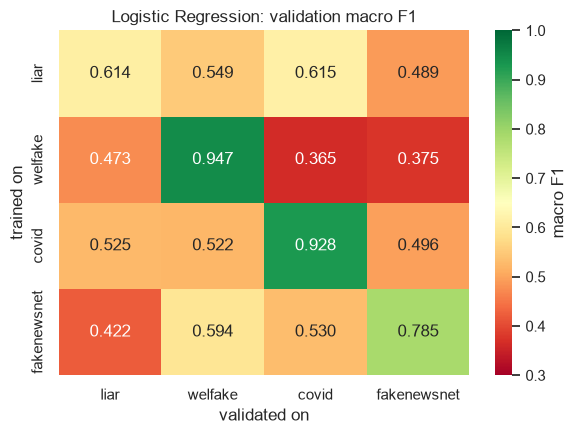

In [7]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(val_f1, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.3, vmax=1.0, cbar_kws={"label": "macro F1"})
plt.title("Logistic Regression: validation macro F1"); plt.tight_layout(); plt.show()

**Reading the table:** the diagonal is each checkpoint on its own dataset (used in Stage 6 to
pick the best model per dataset). Off the diagonal: how well a checkpoint trained on one kind of
text works on another.